Train an SVM model and analyze performance by experimenting with different kernels (linear, polynomial, RBF), optimizing hyperparameters using GridSearchCV, and visualizing decision boundaries for better interpretability.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from scipy import sparse
import joblib
import os

In [2]:
save_folder = "task31_saved_files"
preprocessor = joblib.load(os.path.join(save_folder, "preprocessor.pkl"))
feature_config = joblib.load(os.path.join(save_folder, "feature_config.pkl"))
x_test = joblib.load(os.path.join(save_folder, "x_test.pkl"))
y_test = joblib.load(os.path.join(save_folder, "y_test.pkl"))
x_train = joblib.load(os.path.join(save_folder, "x_train.pkl"))
y_train = joblib.load(os.path.join(save_folder, "y_train.pkl"))
print("All saved files loaded successfully!")

All saved files loaded successfully!


In [4]:
save_folder = "task31_saved_files"

x_train_processed = preprocessor.transform(x_train)
x_test_processed = preprocessor.transform(x_test)

print("Processed training shape:", x_train_processed.shape)
print("Processed testing shape:", x_test_processed.shape)

Processed training shape: (18786, 3049)
Processed testing shape: (4697, 3049)


In [5]:
print("X_train_processed:", x_train_processed.shape)
print("X_test_processed:", x_test_processed.shape)

print("\ny_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

X_train_processed: (18786, 3049)
X_test_processed: (4697, 3049)

y_train: (18786,)
y_test: (4697,)

Training target distribution:
recommend_flag
1    15448
0     3338
Name: count, dtype: int64

Testing target distribution:
recommend_flag
1    3863
0     834
Name: count, dtype: int64


In [6]:
from imblearn.over_sampling import SMOTE

In [7]:
smote = SMOTE(random_state=42)

x_train_svm, y_train_svm = smote.fit_resample(x_train_processed, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_svm).value_counts())

print("\nResampled training shape:", x_train_svm.shape)

Before SMOTE:
recommend_flag
1    15448
0     3338
Name: count, dtype: int64

After SMOTE:
recommend_flag
0    15448
1    15448
Name: count, dtype: int64

Resampled training shape: (30896, 3049)


Prepare data for SVM GridSearchCV

In [8]:
from sklearn.model_selection import train_test_split

x_svm_search, _, y_svm_search, _ = train_test_split(x_train_svm, y_train_svm, train_size=5000, random_state=42, stratify=y_train_svm)

print("SVM tuning sample shape:", x_svm_search.shape)
print("\nClass distribution:")
print(pd.Series(y_svm_search).value_counts())

SVM tuning sample shape: (5000, 3049)

Class distribution:
recommend_flag
0    2500
1    2500
Name: count, dtype: int64


Define SVM kernels and GridSearchCV

In [9]:
svm = SVC(random_state=42, cache_size=1000)

# Define kernel-wise hyperparameter grid
param_grid = [
    {
        "kernel": ["linear"],
        "C": [0.1, 1, 10]
    },
    {
        "kernel": ["poly"],
        "C": [0.1, 1, 10],
        "degree": [2, 3],
        "gamma": ["scale"]
    },
    {
        "kernel": ["rbf"],
        "C": [0.1, 1, 10],
        "gamma": ["scale", "auto"]
    }
]

# Stratified 3-fold cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Grid Search
svm_grid_search = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

svm_grid_search.fit(x_svm_search, y_svm_search)

print("\nBest Parameters:")
print(svm_grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(svm_grid_search.best_score_, 4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters:
{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}

Best Cross-Validation F1 Score:
0.9592


Train the best SVM on complete training data

In [10]:
# Create best SVM model using GridSearchCV parameters
best_svm = SVC(
    kernel='rbf',
    C=10,
    gamma="scale",
    probability=True,
    random_state=42,
    cache_size=1000
)

best_svm.fit(x_train_svm, y_train_svm)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",1000
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Evaluate on untouched test data

In [11]:
svm_y_pred = best_svm.predict(x_test_processed)

svm_y_prob = best_svm.predict_proba(x_test_processed)[:, 1]

svm_results = pd.DataFrame([{
    "Model": "SVM (RBF Kernel)",
    "Accuracy": accuracy_score(y_test, svm_y_pred),
    "Precision": precision_score(y_test, svm_y_pred),
    "Recall": recall_score(y_test, svm_y_pred),
    "F1 Score": f1_score(y_test, svm_y_pred),
    "ROC-AUC": roc_auc_score(y_test, svm_y_prob)
}])

display(svm_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,SVM (RBF Kernel),0.9378,0.967,0.957,0.962,0.9725


Compare SVM with previous models

In [12]:
# Combine previous model results with SVM results

svm_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression L1",
        "Accuracy": 0.9402,
        "Precision": 0.9843,
        "Recall": 0.9423,
        "F1 Score": 0.9628,
        "ROC-AUC": 0.9784
    },
    {
        "Model": "Logistic Regression L2",
        "Accuracy": 0.9402,
        "Precision": 0.9862,
        "Recall": 0.9405,
        "F1 Score": 0.9628,
        "ROC-AUC": 0.9793
    },
    {
        "Model": "Random Forest Tuned",
        "Accuracy": 0.9378,
        "Precision": 0.9641,
        "Recall": 0.9601,
        "F1 Score": 0.9621,
        "ROC-AUC": 0.9720
    },
    {
        "Model": "SVM (RBF Kernel)",
        "Accuracy": 0.9378,
        "Precision": 0.9670,
        "Recall": 0.9570,
        "F1 Score": 0.9620,
        "ROC-AUC": 0.9725
    }
])

display(
    svm_comparison.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression L1,0.9402,0.9843,0.9423,0.9628,0.9784
1,Logistic Regression L2,0.9402,0.9862,0.9405,0.9628,0.9793
2,Random Forest Tuned,0.9378,0.9641,0.9601,0.9621,0.9720
3,SVM (RBF Kernel),0.9378,0.9670,0.9570,0.9620,0.9725


Compare all three SVM kernels

In [13]:
cv_results = pd.DataFrame(svm_grid_search.cv_results_)

kernel_results = []

for kernel_name in ['linear', 'poly', 'rbf']:

    kernel_data = cv_results[cv_results['param_kernel']==kernel_name]
    best_row = kernel_data.loc[kernel_data['mean_test_score'].idxmax()]

    best_params = best_row["params"]

    print(f"\nTraining {kernel_name} kernel")
    print("Best parameters:", best_params)

    kernel_model = SVC(**best_params, probability=True, random_state=42, cache_size=1000)

    kernel_model.fit(x_train_svm, y_train_svm)

    y_pred_kernel = kernel_model.predict(x_test_processed)
    y_prob_kernel = kernel_model.predict_proba(x_test_processed)[:, 1]

    kernel_results.append({
        "Kernel": kernel_name,
        "Best Parameters": str(best_params),
        "Accuracy": accuracy_score(y_test, y_pred_kernel),
        "Precision": precision_score(y_test, y_pred_kernel),
        "Recall": recall_score(y_test, y_pred_kernel),
        "F1 Score": f1_score(y_test, y_pred_kernel),
        "ROC-AUC": roc_auc_score(y_test, y_prob_kernel)
    })

# Display comparison
kernel_comparison_df = pd.DataFrame(kernel_results)

display(
    kernel_comparison_df
    .sort_values("F1 Score", ascending=False)
    .round(4)
)


Training linear kernel
Best parameters: {'C': 1, 'kernel': 'linear'}

Training poly kernel
Best parameters: {'C': 1, 'degree': 2, 'gamma': 'scale', 'kernel': 'poly'}

Training rbf kernel
Best parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}


,Kernel,Best Parameters,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,rbf,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}",0.9378,0.9670,0.9570,0.9620,0.9725
0,linear,"{'C': 1, 'kernel': 'linear'}",0.9346,0.9790,0.9407,0.9595,0.9769
1,poly,"{'C': 1, 'degree': 2, 'gamma': 'scale', 'kernel': 'poly'}",0.9351,0.9877,0.9327,0.9594,0.9762


Performance comparison chart

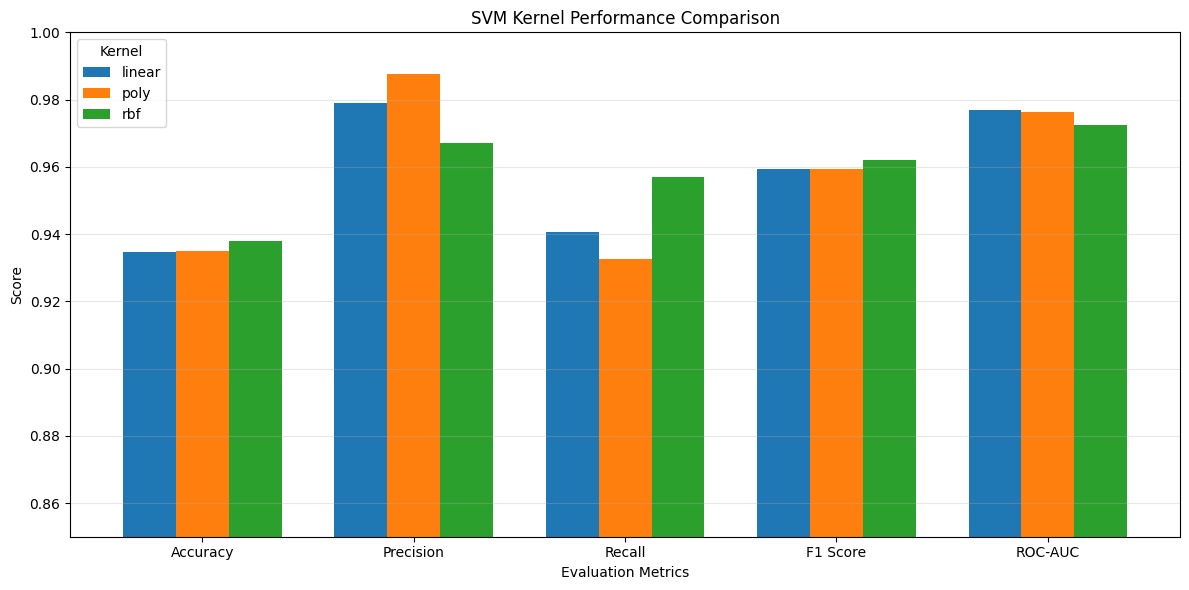

In [14]:

metrics = [
    "Accuracy", "Precision", "Recall",
    "F1 Score", "ROC-AUC"
]

plot_df = kernel_comparison_df.set_index("Kernel")[metrics]

ax = plot_df.T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("SVM Kernel Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0.85, 1.0)
plt.xticks(rotation=0)
plt.legend(title="Kernel")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


SVM Decision Boundary Visualization using PCA

In [16]:
# Select 3000 rows for visualization
x_vis, _, y_vis, _ = train_test_split(x_train_svm, y_train_svm, train_size=3000, random_state=42, stratify=y_train_svm)

# Convert selected sparse data to dense
x_vis_dense = (
    x_vis.toarray()
    if sparse.issparse(x_vis) else np.asarray(x_vis)
)
print("Visualization data shape:", x_vis_dense.shape)

Visualization data shape: (3000, 3049)


Apply PCA

In [18]:
pca = PCA(n_components=2, random_state=42)
x_vis_2d = pca.fit_transform(x_vis_dense)
print("PCA transformed shape:", x_vis_2d.shape)


print("Explained variance ratio by PCA components:", pca.explained_variance_ratio_)
print("Total explained variance:", np.sum(pca.explained_variance_ratio_))

PCA transformed shape: (3000, 2)
Explained variance ratio by PCA components: [0.37088968 0.11651521]
Total explained variance: 0.48740488997116704


Train an illustrative 2D RBF SVM

In [21]:
visual_svm = SVC(
    kernel='rbf',
    C=10,
    gamma="scale",
    probability=True,
    random_state=42,
    cache_size=1000
)

visual_svm.fit(x_vis_2d, y_vis)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",1000
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Plot the decision boundary

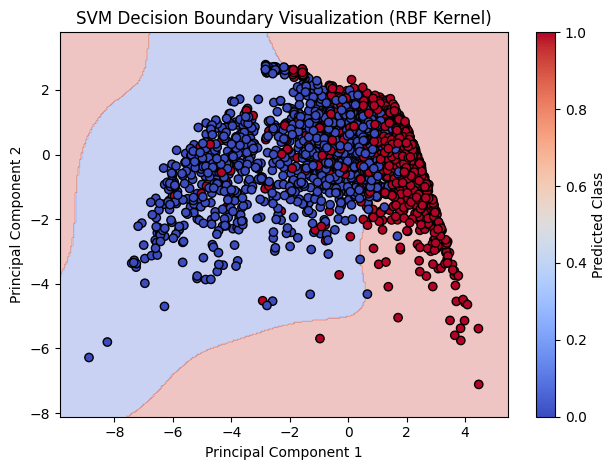

In [22]:
# Create mesh grid
x_min, x_max = x_vis_2d[:, 0].min() - 1, x_vis_2d[:, 0].max() + 1
y_min, y_max = x_vis_2d[:, 1].min() - 1, x_vis_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict over the grid
z = visual_svm.predict(np.c_[xx.ravel(), yy.ravel()])

z = z.reshape(xx.shape)

# Predict over the grid
plt.contourf(xx, yy, z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(x_vis_2d[:, 0], x_vis_2d[:, 1], c=y_vis, edgecolors='k', cmap=plt.cm.coolwarm)
plt.title("SVM Decision Boundary Visualization (RBF Kernel)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Predicted Class")
plt.tight_layout()
plt.show()

Final Conclusion : Support Vector Machine (SVM)
The Support Vector Machine (SVM) algorithm was implemented and evaluated using three different kernels: Linear, Polynomial, and Radial Basis Function (RBF). GridSearchCV was used to identify the optimal hyperparameters for each kernel and improve model performance.

The RBF kernel achieved the highest accuracy of 93.78%, recall of 95.70%, and F1-score of 96.20%, demonstrating the best overall balance among the three kernels. The Linear kernel achieved the highest ROC-AUC of 97.69%, while the Polynomial kernel achieved the highest precision of 98.77%.

A decision boundary visualization was generated using Principal Component Analysis (PCA) to reduce the feature space to two dimensions. The plot illustrates how the RBF SVM separates the two recommendation classes. Some overlap between the blue and red data points is visible, indicating that the classes are not completely separable in the two-dimensional projection.

Overall, the RBF kernel provided the strongest balance of classification performance, while all three kernels demonstrated effective predictive capabilities. The 2D decision boundary is an illustrative visualization based on a separately trained model, not the exact boundary of the original 3,049-feature SVM.